In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Basic Preprocasing

In [ ]:
indian = pd.read_excel("D:\\SevenMentor\\ML\\workspace\\Dataset\\Indian_Economy_Sectorwise_Dataset.xlsx")

In [ ]:
indian.head()

,Year,Quarter,Sector,GDP_Lakh_Crore,Growth_%,Employment_Million,Exports_Crore,Imports_Crore,FDI_Crore,Inflation_%,CPI,IIP,Tax_Revenue_Crore
0,2015,Q1,Agriculture,29.72,3.94,52.1,107539,126895,27477,4.71,163,95,123957
1,2015,Q1,Manufacturing,37.35,9.86,7.7,47744,90509,2292,4.81,121,88,184005
2,2015,Q1,Construction,64.71,6.01,42.4,58226,121494,26803,6.88,114,115,198671
3,2015,Q1,Mining,30.02,9.53,21.4,56195,66624,15163,4.69,158,100,91599
4,2015,Q1,Electricity,50.47,9.75,219.5,96330,98575,20985,6.71,130,131,266982


In [ ]:
indian["Year"].unique()

array([2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025])

In [ ]:
indian["Sector"].unique()

<StringArray>
[          'Agriculture',         'Manufacturing',          'Construction',
                'Mining',           'Electricity',           'IT Services',
    'Financial Services',                'Retail',            'Healthcare',
             'Education',             'Transport',               'Tourism',
           'Real Estate',         'Communication', 'Public Administration']
Length: 15, dtype: str

In [ ]:
indian.isnull().sum()

Year                  0
Quarter               0
Sector                0
GDP_Lakh_Crore        0
Growth_%              0
Employment_Million    0
Exports_Crore         0
Imports_Crore         0
FDI_Crore             0
Inflation_%           0
CPI                   0
IIP                   0
Tax_Revenue_Crore     0
dtype: int64

In [ ]:
indian.duplicated().sum()

np.int64(0)

In [ ]:
indian.columns

Index(['Year', 'Quarter', 'Sector', 'GDP_Lakh_Crore', 'Growth_%',
       'Employment_Million', 'Exports_Crore', 'Imports_Crore', 'FDI_Crore',
       'Inflation_%', 'CPI', 'IIP', 'Tax_Revenue_Crore'],
      dtype='str')

# Standard deviation of growth rates across sectors during macro events.

In [ ]:
COVID_19_2020 = [2019, 2020]
Demonetisation_2016 = [2015, 2016]
GST_rollout_2017 = [2017, 2018]
years_of_interest = COVID_19_2020 + Demonetisation_2016 + GST_rollout_2017

In [ ]:

# convert into data type and create day and month column


# Example: '2015 Q1', '2015 Q2', ...
indian["Time"] = indian["Year"].astype(str) + " " + indian["Quarter"]

# or convert to a proper datetime (assuming Q1=March, Q2=June, etc.)
quarter_to_month = {"Q1": 3, "Q2": 6, "Q3": 9, "Q4": 12}
indian["Month"] = indian["Quarter"].map(quarter_to_month)
indian["Date"] = pd.to_datetime(dict(year=indian["Year"], month=indian["Month"], day=1))

In [ ]:
# Filter data for each event
# -----------------------------
indian_crisis_year = indian[indian['Year'].isin(COVID_19_2020)].reset_index(drop=True)
indian_Demonetisation_year = indian[indian['Year'].isin(Demonetisation_2016)].reset_index(drop=True)
indian_gst_year = indian[indian['Year'].isin(GST_rollout_2017)].reset_index(drop=True)

### Sector Std on Growth_%

In [ ]:
# Group by as per sector on Growth_%
# -------------------------------------
indian_crisis_std = indian_crisis_year.groupby("Sector")["Growth_%"].std().reset_index(name='Std_Growth_across_sectors')
indian_Demonetisation_std = indian_Demonetisation_year.groupby("Sector")["Growth_%"].std().reset_index(name='Std_Growth_across_sectors')
indian_gst_std = indian_gst_year.groupby("Sector")["Growth_%"].std().reset_index(name='Std_Growth_across_sectors')

In [ ]:
print("indian_crisis_year:\n",indian_crisis_std, "\n")
print("indian_Demonetisation_year:\n",indian_Demonetisation_std, "\n")
print("indian_gst_year:\n",indian_gst_std, "\n")

indian_crisis_year:
                    Sector  Std_Growth_across_sectors
0             Agriculture                   3.735298
1           Communication                   2.699878
2            Construction                   2.954536
3               Education                   2.937384
4             Electricity                   3.926331
5      Financial Services                   2.877727
6              Healthcare                   3.590542
7             IT Services                   2.764958
8           Manufacturing                   3.924345
9                  Mining                   3.823655
10  Public Administration                   2.933080
11            Real Estate                   3.543429
12                 Retail                   3.467776
13                Tourism                   3.340139
14              Transport                   2.579092 

indian_Demonetisation_year:
                    Sector  Std_Growth_across_sectors
0             Agriculture                   2.3

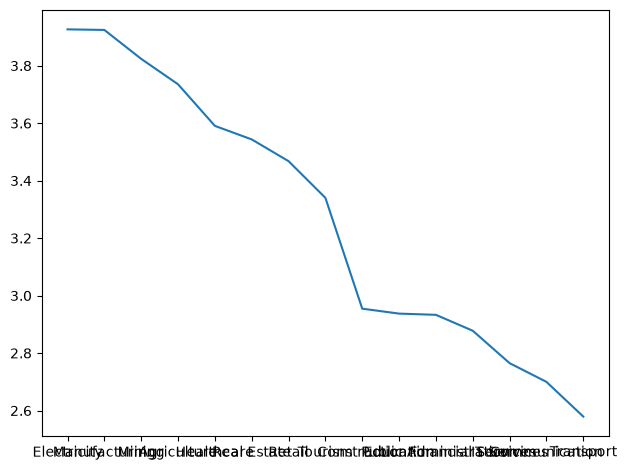

In [ ]:
# Plot
plt.Figure(figsize=(10,6))
a = indian_crisis_std.sort_values(by='Std_Growth_across_sectors', ascending=False)
plt.plot(a['Sector'], a['Std_Growth_across_sectors'])
# indian_Demonetisation_std.sort_values(by='Std_Growth_across_sectors', ascending=False).plot.bar(x='Sector', y='Std_Growth_across_sectors', title='Standard Deviation of Growth % across Sectors during Demonetisation (2015-2016)', legend = False)
# indian_gst_std.sort_values(by='Std_Growth_across_sectors', ascending=False).plot.bar(x='Sector', y='Std_Growth_across_sectors', title='Standard Deviation of Growth % across Sectors during GST Rollout (2017-2018)', legend = False)
plt.tight_layout()

### Growth of define sector accorss years


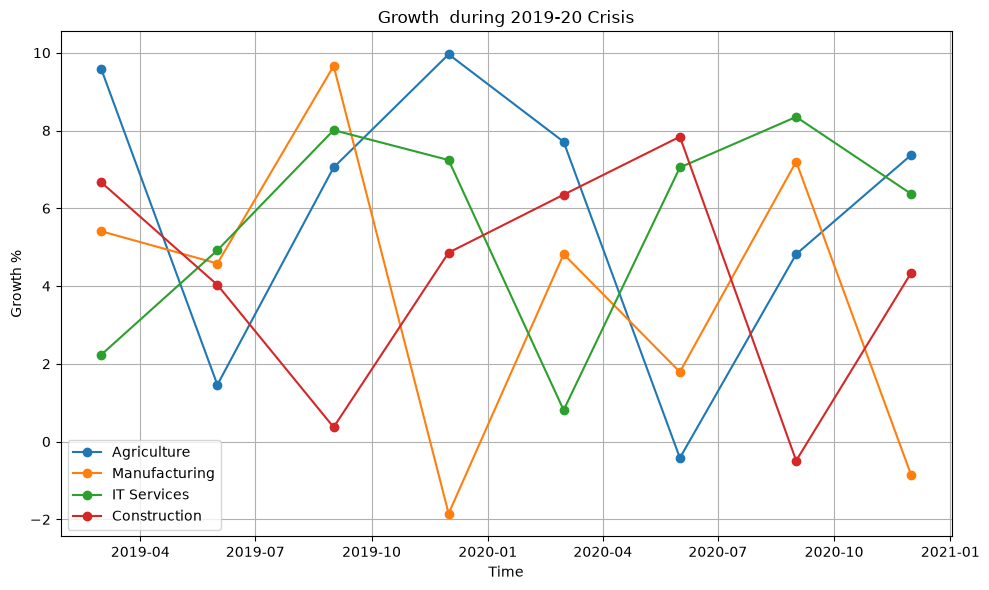

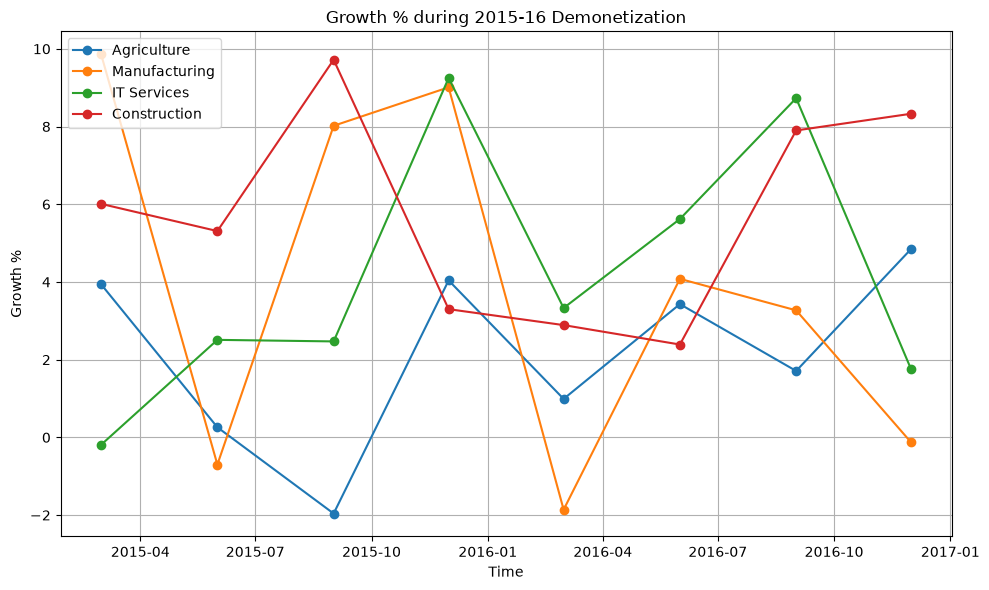

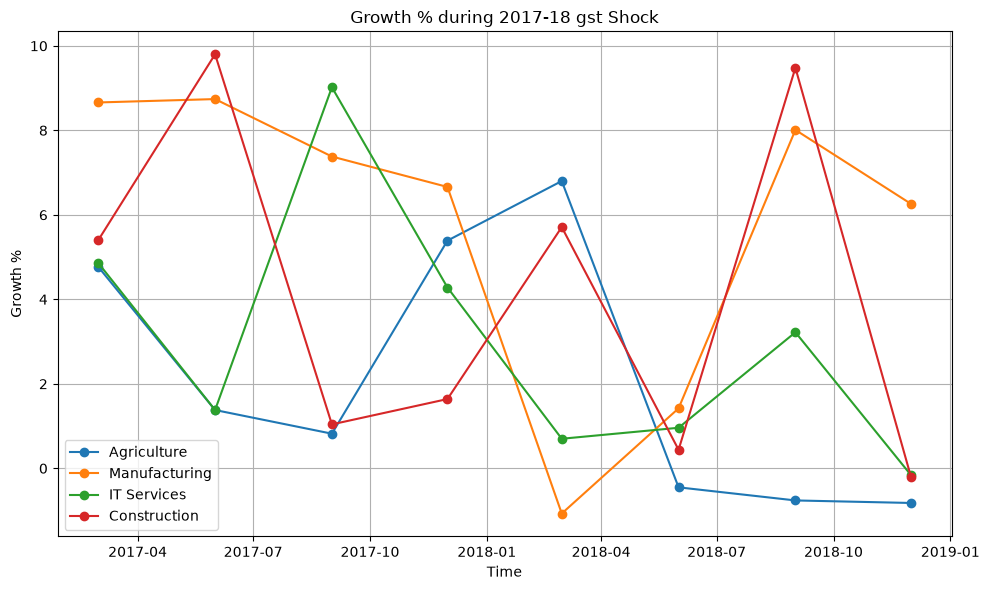

In [ ]:
# Plot on choose key sectors
key_sectors = ["Agriculture", "Manufacturing", "IT Services", "Construction"]

# Helper to plot one event window
def plot_event(df_window, title):
    df_plot = df_window[df_window["Sector"].isin(key_sectors)].copy()
    df_plot = df_plot.sort_values(["Date"])

    plt.figure(figsize=(10, 6))
    for sector in key_sectors:
        sector_data = df_plot[df_plot["Sector"] == sector]
        plt.plot(sector_data["Date"], sector_data["Growth_%"],  label=sector, marker='o')

    plt.title(title)
    plt.xlabel("Time")
    plt.ylabel("Growth %")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

plot_event(indian_crisis_year, "Growth  during 2019-20 Crisis")
plot_event(indian_Demonetisation_year, "Growth % during 2015-16 Demonetization")
plot_event(indian_gst_year, "Growth % during 2017-18 gst Shock")

### Sector Std on GDP

In [ ]:
# now as per gdp_crores
indian_crisis_std_gdp = indian_crisis_year.groupby("Sector")["GDP_Lakh_Crore"].std().reset_index()
indian_Demonetisation_std_gdp = indian_Demonetisation_year.groupby("Sector")["GDP_Lakh_Crore"].std().reset_index()
indian_gst_std_gdp = indian_gst_year.groupby("Sector")["GDP_Lakh_Crore"].std().reset_index()
# indian_crisis_year_gdp = indian_crisis_year.groupby("year")["GDP"]


In [ ]:
print("Std of gdp of Demonetisation Year(2015, 2016): \n",indian_Demonetisation_std_gdp)
print("Std of gdp of GST Year(2017, 2018): \n", indian_gst_std_gdp)
print("Std of gdp of Crisis Year(2019, 2020): \n", indian_crisis_std_gdp)

Std of gdp of Demonetisation Year(2015, 2016): 
                    Sector  GDP_Lakh_Crore
0             Agriculture       21.892543
1           Communication       18.533410
2            Construction       17.377781
3               Education       20.948436
4             Electricity       23.806616
5      Financial Services       18.140643
6              Healthcare       19.897068
7             IT Services       13.529700
8           Manufacturing       21.259621
9                  Mining       22.770969
10  Public Administration       21.628051
11            Real Estate       20.769199
12                 Retail       24.049995
13                Tourism       16.365634
14              Transport       25.261863
Std of gdp of GST Year(2017, 2018): 
                    Sector  GDP_Lakh_Crore
0             Agriculture       20.817468
1           Communication       19.915261
2            Construction       22.292818
3               Education       23.337755
4             Electricity      

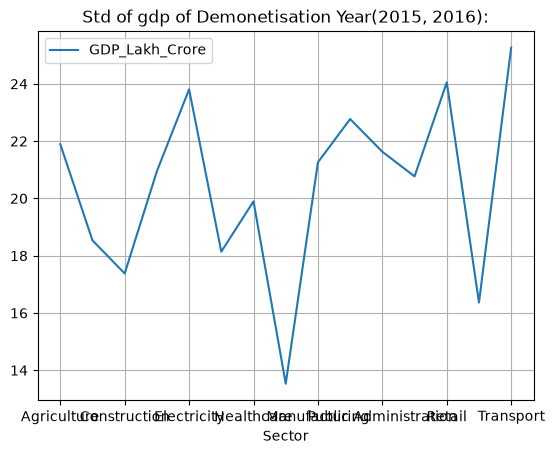

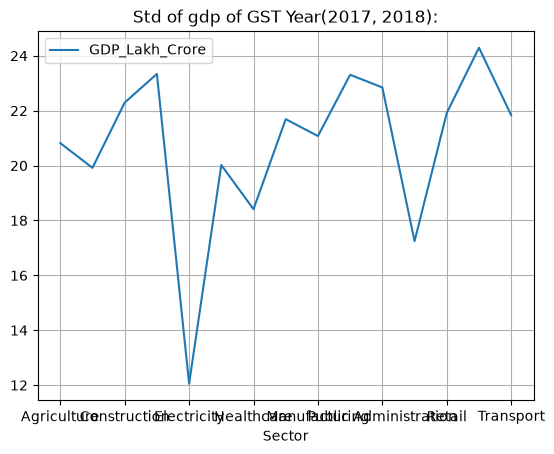

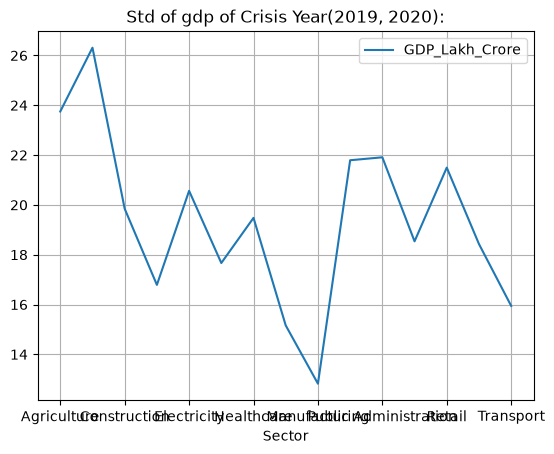

In [ ]:
#line chart

def plot(table, name):
    table.plot(x = "Sector", y = "GDP_Lakh_Crore")
    plt.title(name)
    plt.grid()


plot(indian_Demonetisation_std_gdp, "Std of gdp of Demonetisation Year(2015, 2016):")
plot(indian_gst_std_gdp, "Std of gdp of GST Year(2017, 2018):")
plot(indian_crisis_std_gdp, "Std of gdp of Crisis Year(2019, 2020):")

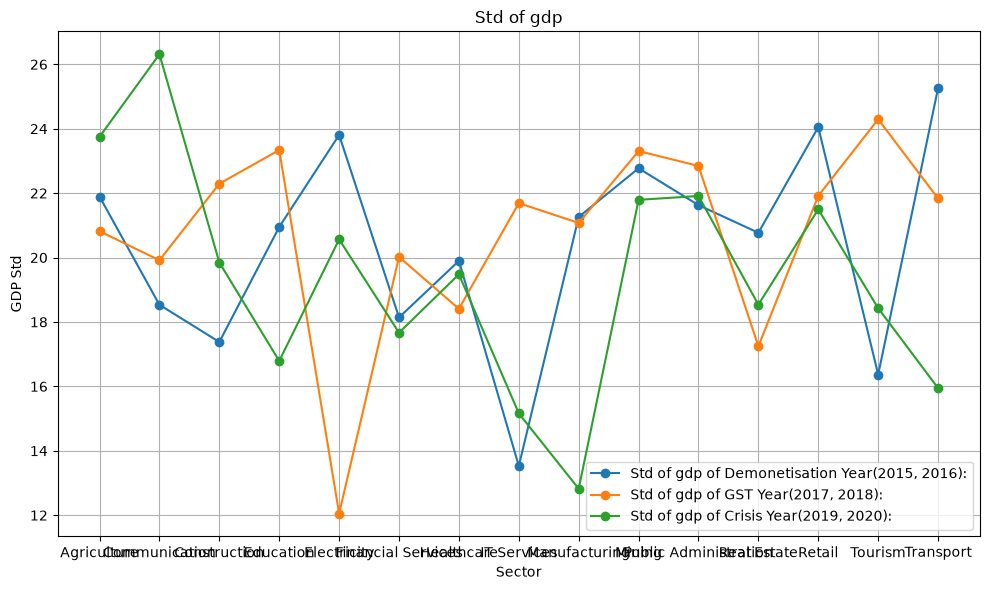

In [ ]:
plt.figure(figsize=(10, 6))

# for col in pivot.columns:
#     plt.plot(pivot.index, pivot[col], marker='o', label=col)
def plot(table, name):
    plt.plot(table.Sector, table['GDP_Lakh_Crore'],   label= name, marker='o')
    # plt.plot(indian_gst_std_gdp.Sector, indian_gst_std_gdp['GDP_Lakh_Crore'], label='gst_std_gdp', marker='o')
    # plt.plot(indian_crisis_std_gdp.Sector, indian_crisis_std_gdp['GDP_Lakh_Crore'],  label='crisis_std_gdp', marker='o')

plot(indian_Demonetisation_std_gdp, "Std of gdp of Demonetisation Year(2015, 2016):")
plot(indian_gst_std_gdp, "Std of gdp of GST Year(2017, 2018):")
plot(indian_crisis_std_gdp, "Std of gdp of Crisis Year(2019, 2020):")

plt.xlabel('Sector', loc='center')
plt.ylabel('GDP Std' )
plt.title('Std of gdp')
plt.legend()
plt.grid(True)
plt.tight_layout()

# show on screen
plt.show()

In [ ]:
# indian_gst_std_gdp.sort_values(by= "indian_gst_std_gdp").plot(kind="bar", x="Sector", y = "indian_gst_std_gdp")

### Sector Std on Inflation_%

In [ ]:
indian_Crisis_std_inflation = indian_crisis_year.groupby("Sector")["Inflation_%"].std().reset_index()
indian_Demonetisation_std_inflation = indian_Demonetisation_year.groupby("Sector")["Inflation_%"].std().reset_index()
indian_Gst_std_inflation = indian_gst_year.groupby("Sector")["Inflation_%"].std().reset_index()


In [ ]:
print("Std_of_Crisis_by_inflation \n", indian_Crisis_std_inflation, "\n")
print("Std_of_GST_by_inflation \n", indian_Gst_std_inflation, "\n")
print("Std_of_Demonetion_by_inflation \n", indian_Demonetisation_std_inflation, "\n")

Std_of_Crisis_by_inflation 
                    Sector  Inflation_%
0             Agriculture     1.225176
1           Communication     1.257406
2            Construction     1.682719
3               Education     1.695161
4             Electricity     1.882513
5      Financial Services     2.188695
6              Healthcare     1.085968
7             IT Services     1.859806
8           Manufacturing     1.429580
9                  Mining     2.098283
10  Public Administration     0.915107
11            Real Estate     1.865192
12                 Retail     1.440490
13                Tourism     1.723008
14              Transport     2.141266 

Std_of_GST_by_inflation 
                    Sector  Inflation_%
0             Agriculture     1.815922
1           Communication     1.875715
2            Construction     1.719318
3               Education     1.712776
4             Electricity     1.922843
5      Financial Services     1.425112
6              Healthcare     1.568138
7      

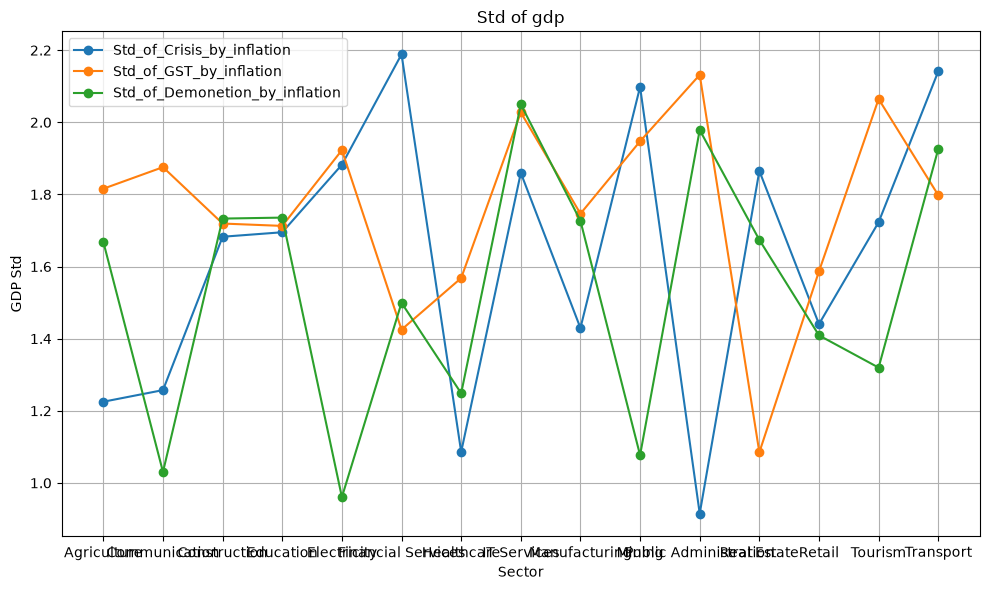

In [ ]:

plt.figure(figsize=(10, 6))

def plot(table, name):
    plt.plot(table.Sector, table['Inflation_%'],   label= name, marker='o')


plot(indian_Crisis_std_inflation, "Std_of_Crisis_by_inflation")
plot(indian_Gst_std_inflation, "Std_of_GST_by_inflation")
plot(indian_Demonetisation_std_inflation, "Std_of_Demonetion_by_inflation")

plt.xlabel('Sector', loc='center')
plt.ylabel('GDP Std' )
plt.title('Std of gdp')
plt.legend()
plt.grid(True)
plt.tight_layout()

# show on screen
plt.show()

In [ ]:
indian["Sector"].unique()

<StringArray>
[          'Agriculture',         'Manufacturing',          'Construction',
                'Mining',           'Electricity',           'IT Services',
    'Financial Services',                'Retail',            'Healthcare',
             'Education',             'Transport',               'Tourism',
           'Real Estate',         'Communication', 'Public Administration']
Length: 15, dtype: str

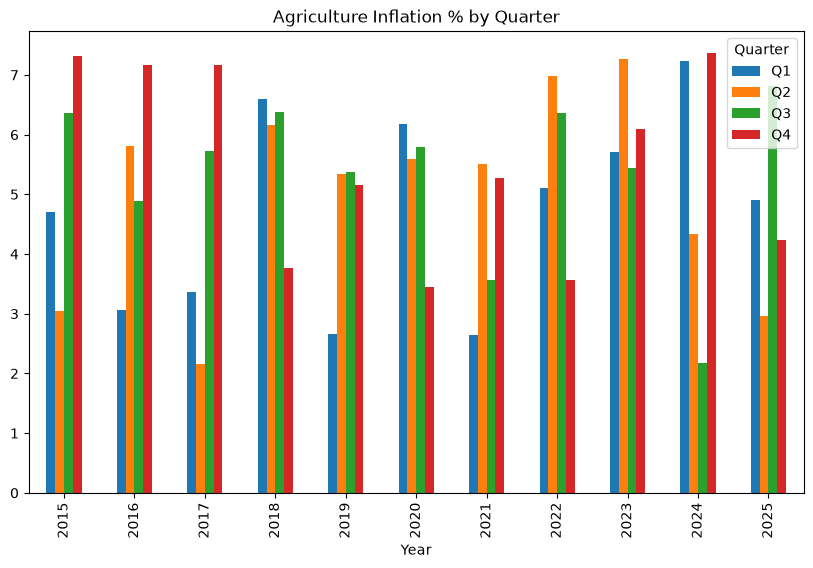

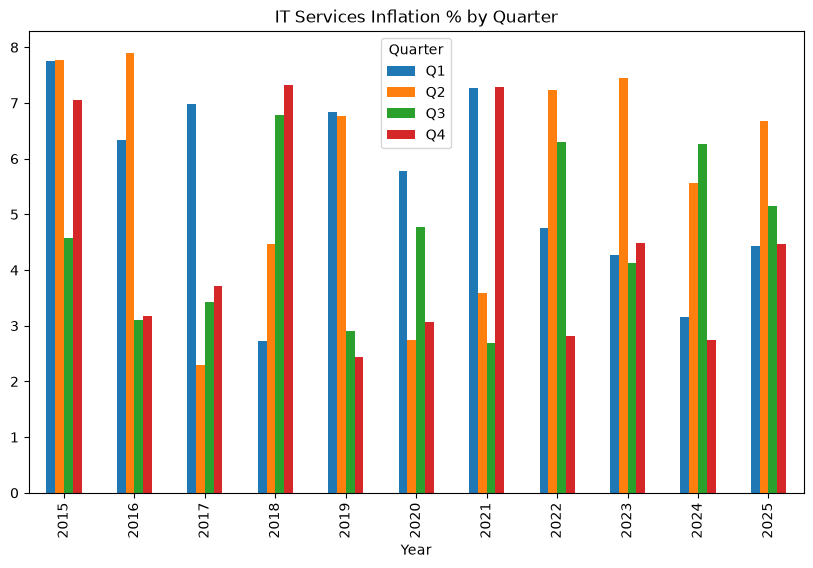

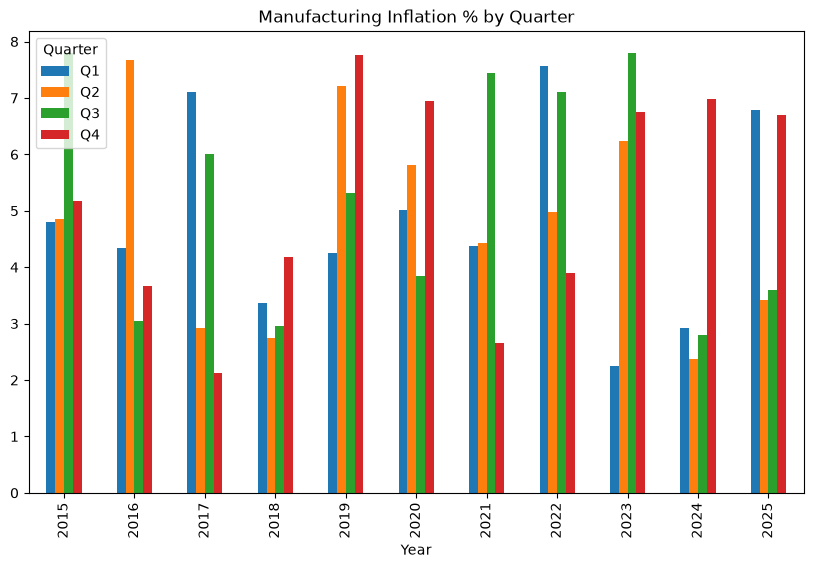

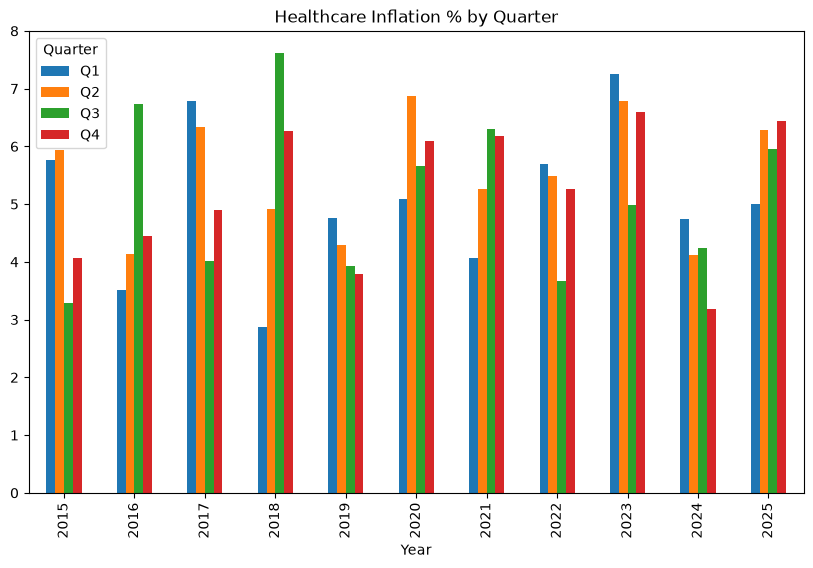

In [ ]:
key_sector = ["Agriculture", "IT Services", "Manufacturing", "Healthcare"]

for x in key_sector:

    a = indian[indian["Sector"]==x][["Year", "Quarter", "Sector", "Inflation_%"]].reset_index(drop=True)
    pivot_table = a.pivot_table(index=["Year"], columns="Quarter", values="Inflation_%")
    pivot_table.plot(kind="bar", title=f"{x} Inflation % by Quarter", figsize=(10, 6))



# Divide sector in group 

 Primary sector: activities that use natural resources directly from nature, like agriculture and mining.

 Secondary sector: activities that transform raw materials into finished goods, like manufacturing and construction.
 
 Tertiary sector: activities that provide services, like transport, retail, healthcare, and finance.

 Quaternary sector: activities based on knowledge, information, research, and technology

In [ ]:
# defining the important sectors
# 1 nature resources
primary_sectors = ["Agriculture", "Mining"]

# 2 industrial resources
secondary_sectors = ["Manufacturing", "Construction", "Electricity", "Real Estate"]


# 3 service resources
tertiary_sectors = ["Retail", "Healthcare", "Transport", "Tourism", "Financial Services", "Communication"]


# 4. other sectors
# total_sectors = primary_sectors + secondary_sectors + tertiary_sectors
# l = indian['Sector'].unique()
# other_sectors = [sector for sector in l if sector not in total_sectors]

other_sectors = ['IT Services', 'Education', 'Public Administration']

In [ ]:
other_sectors

['IT Services', 'Education', 'Public Administration']

In [ ]:
def plot_sector(x):
    if x in primary_sectors:
        return 'Primary Sector'
    elif x in secondary_sectors:
        return 'Secondary Sector'
    elif x in tertiary_sectors:
        return 'Tertiary Sector'
    else:
        return 'Other Sector'


indian['Sector_Type'] = indian['Sector'].apply(plot_sector)

In [ ]:
# aggragete gda by year, sector type

g  = (
        indian.groupby(["Year", "Sector_Type"], as_index=False)["GDP_Lakh_Crore"].sum()

    )
g

,Year,Sector_Type,GDP_Lakh_Crore
0,2015,Other Sector,576.56
1,2015,Primary Sector,279.99
2,2015,Secondary Sector,926.30
3,2015,Tertiary Sector,1056.28
4,2016,Other Sector,677.37
5,2016,Primary Sector,337.63
6,2016,Secondary Sector,611.27
7,2016,Tertiary Sector,968.90
8,2017,Other Sector,588.68
9,2017,Primary Sector,414.35


In [ ]:
# Compute total and percentage share
g["year_of_total"] = g.groupby("Year")["GDP_Lakh_Crore"].transform(sum)
g['Percentage_Share'] = (g['GDP_Lakh_Crore'] / g['year_of_total']) * 100
g

,Year,Sector_Type,GDP_Lakh_Crore,year_of_total,Percentage_Share
0,2015,Other Sector,576.56,2839.13,20.307629
1,2015,Primary Sector,279.99,2839.13,9.861824
2,2015,Secondary Sector,926.30,2839.13,32.626192
3,2015,Tertiary Sector,1056.28,2839.13,37.204355
4,2016,Other Sector,677.37,2595.17,26.101180
5,2016,Primary Sector,337.63,2595.17,13.009938
6,2016,Secondary Sector,611.27,2595.17,23.554141
7,2016,Tertiary Sector,968.90,2595.17,37.334741
8,2017,Other Sector,588.68,2767.39,21.272029
9,2017,Primary Sector,414.35,2767.39,14.972592


In [ ]:
#  Pivot to wide format: one column per sector

pivot = g.pivot(index='Year', columns='Sector_Type', values='Percentage_Share').fillna(0)
pivot = pivot.sort_index()  # ensure years in order

display(pivot)

Sector_Type,Other Sector,Primary Sector,Secondary Sector,Tertiary Sector
Year,,,,
2015,20.307629,9.861824,32.626192,37.204355
2016,26.101180,13.009938,23.554141,37.334741
2017,21.272029,14.972592,26.532220,37.223160
2018,15.891881,14.589697,28.416799,41.101622
2019,16.503894,15.408937,26.842472,41.244697
2020,21.378575,12.241929,26.609206,39.770290
2021,19.470501,14.761721,24.798274,40.969504
2022,15.958107,12.784157,28.659621,42.598115
2023,18.803950,13.440045,25.638252,42.117754


In [ ]:
df = pd.DataFrame(pivot).reset_index()
df

Sector_Type,Year,Other Sector,Primary Sector,Secondary Sector,Tertiary Sector
0,2015,20.307629,9.861824,32.626192,37.204355
1,2016,26.101180,13.009938,23.554141,37.334741
2,2017,21.272029,14.972592,26.532220,37.223160
3,2018,15.891881,14.589697,28.416799,41.101622
4,2019,16.503894,15.408937,26.842472,41.244697
5,2020,21.378575,12.241929,26.609206,39.770290
6,2021,19.470501,14.761721,24.798274,40.969504
7,2022,15.958107,12.784157,28.659621,42.598115
8,2023,18.803950,13.440045,25.638252,42.117754
9,2024,18.246952,14.293098,28.211451,39.248499


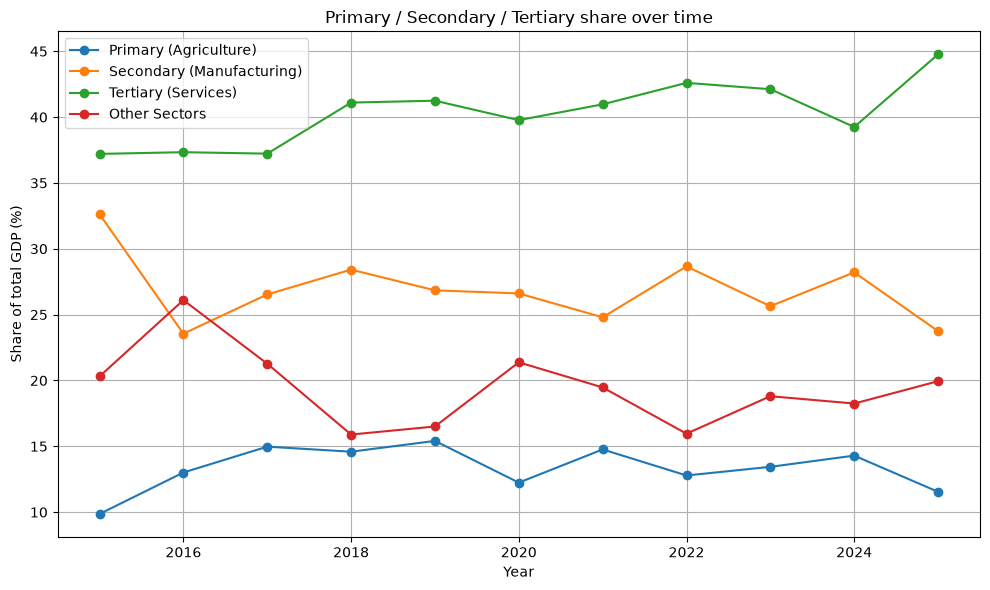

In [ ]:
# ------------------------
# 5. Line plot over years
# ------------------------
plt.figure(figsize=(10, 6))

# for col in pivot.columns:
#     plt.plot(pivot.index, pivot[col], marker='o', label=col)
plt.plot(pivot.index, pivot['Primary Sector'],   label='Primary (Agriculture)', marker='o')
plt.plot(pivot.index, pivot['Secondary Sector'], label='Secondary (Manufacturing)', marker='o')
plt.plot(pivot.index, pivot['Tertiary Sector'],  label='Tertiary (Services)', marker='o')
plt.plot(pivot.index, pivot['Other Sector'],     label='Other Sectors', marker='o')

plt.xlabel('Year')
plt.ylabel('Share of total GDP (%)')
plt.title('Primary / Secondary / Tertiary share over time')
plt.legend()
plt.grid(True)
plt.tight_layout()

# show on screen
plt.show()



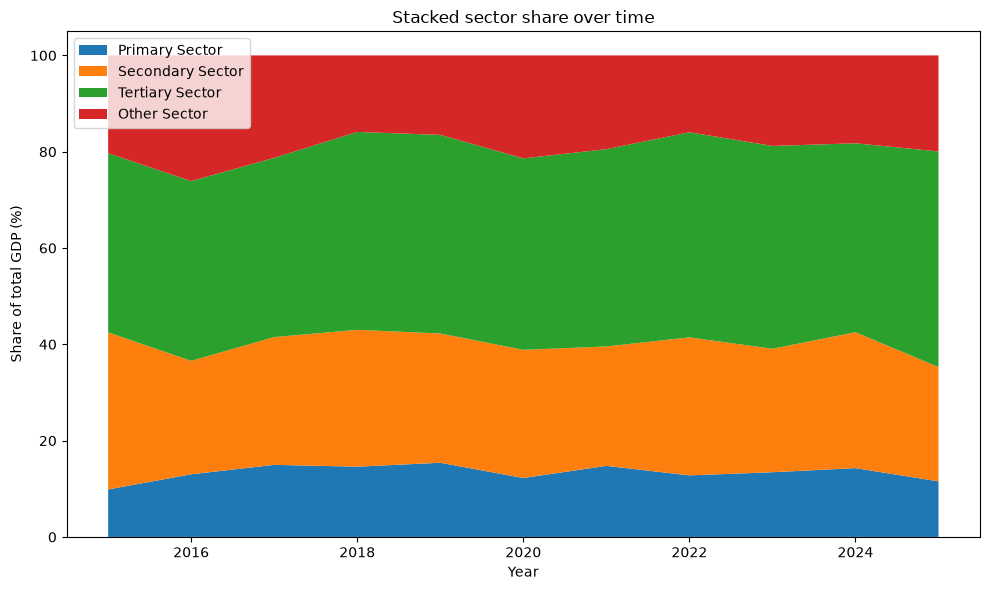

In [ ]:
# # save as PNG
# plt.savefig('sector_share_line.png', dpi=300)

# ---------------------------------
# 6. Stacked area chart (optional)
# ---------------------------------
plt.figure(figsize=(10, 6))

plt.stackplot(
    pivot.index,
    pivot['Primary Sector'],
    pivot['Secondary Sector'],
    pivot['Tertiary Sector'],
    pivot['Other Sector'],
    labels=['Primary Sector', 'Secondary Sector', 'Tertiary Sector', 'Other Sector']
)

plt.xlabel('Year')
plt.ylabel('Share of total GDP (%)')
plt.title('Stacked sector share over time')
plt.legend(loc='upper left')
plt.tight_layout()

plt.show()
# plt.savefig('sector_share_stacked.png', dpi=300)

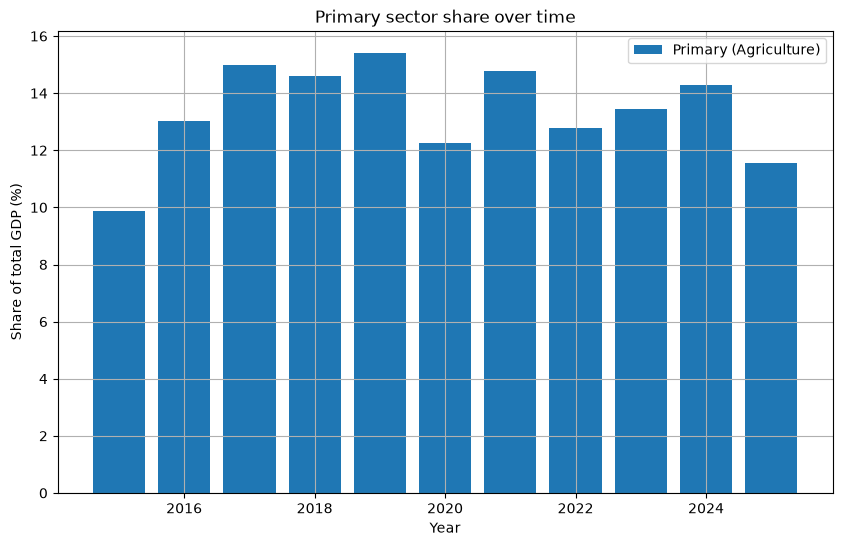

In [ ]:
plt.figure(figsize=(10, 6))
plt.bar(
    df['Year'],
    df['Primary Sector'],
    label='Primary (Agriculture)'
)
plt.xlabel('Year')
plt.ylabel('Share of total GDP (%)')
plt.title('Primary sector share over time')
plt.legend()
plt.grid(True)
plt.show()


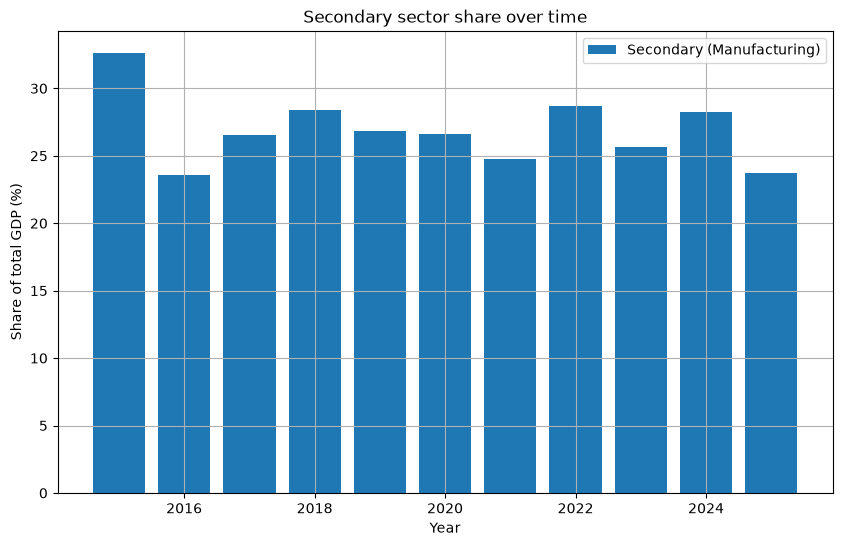

In [ ]:
plt.figure(figsize=(10, 6))
plt.bar(
    df['Year'],
    df['Secondary Sector'],
    label='Secondary (Manufacturing)'
)
plt.xlabel('Year')
plt.ylabel('Share of total GDP (%)')
plt.title('Secondary sector share over time')
plt.legend()
plt.grid(True)
plt.show()


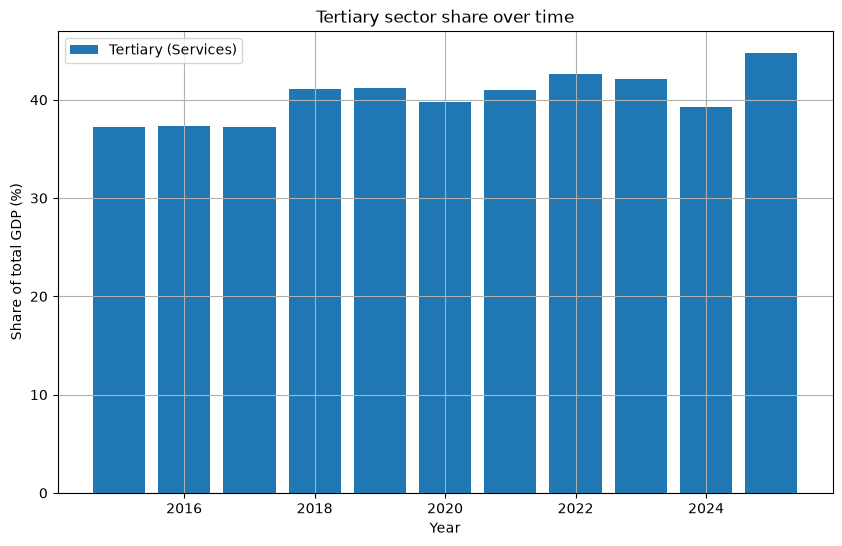

In [ ]:
plt.figure(figsize=(10, 6))
plt.bar(
    df['Year'],
    df['Tertiary Sector'],
    label='Tertiary (Services)'
)
plt.xlabel('Year')
plt.ylabel('Share of total GDP (%)')
plt.title('Tertiary sector share over time')
plt.legend()
plt.grid(True)
plt.show()


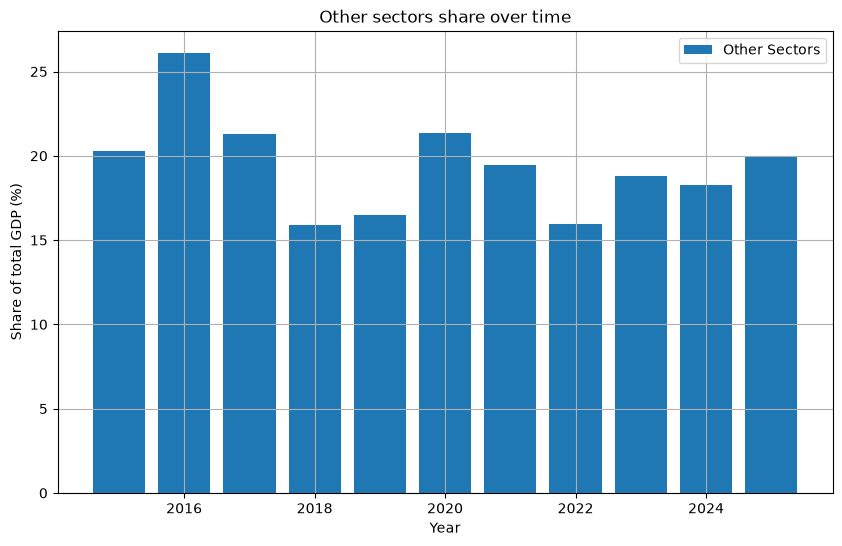

In [ ]:
plt.figure(figsize=(10, 6))
plt.bar(
    df['Year'],
    df['Other Sector'],
    label='Other Sectors'
)

plt.xlabel('Year')
plt.ylabel('Share of total GDP (%)')
plt.title('Other sectors share over time')
plt.legend()
plt.grid(True)
plt.show()


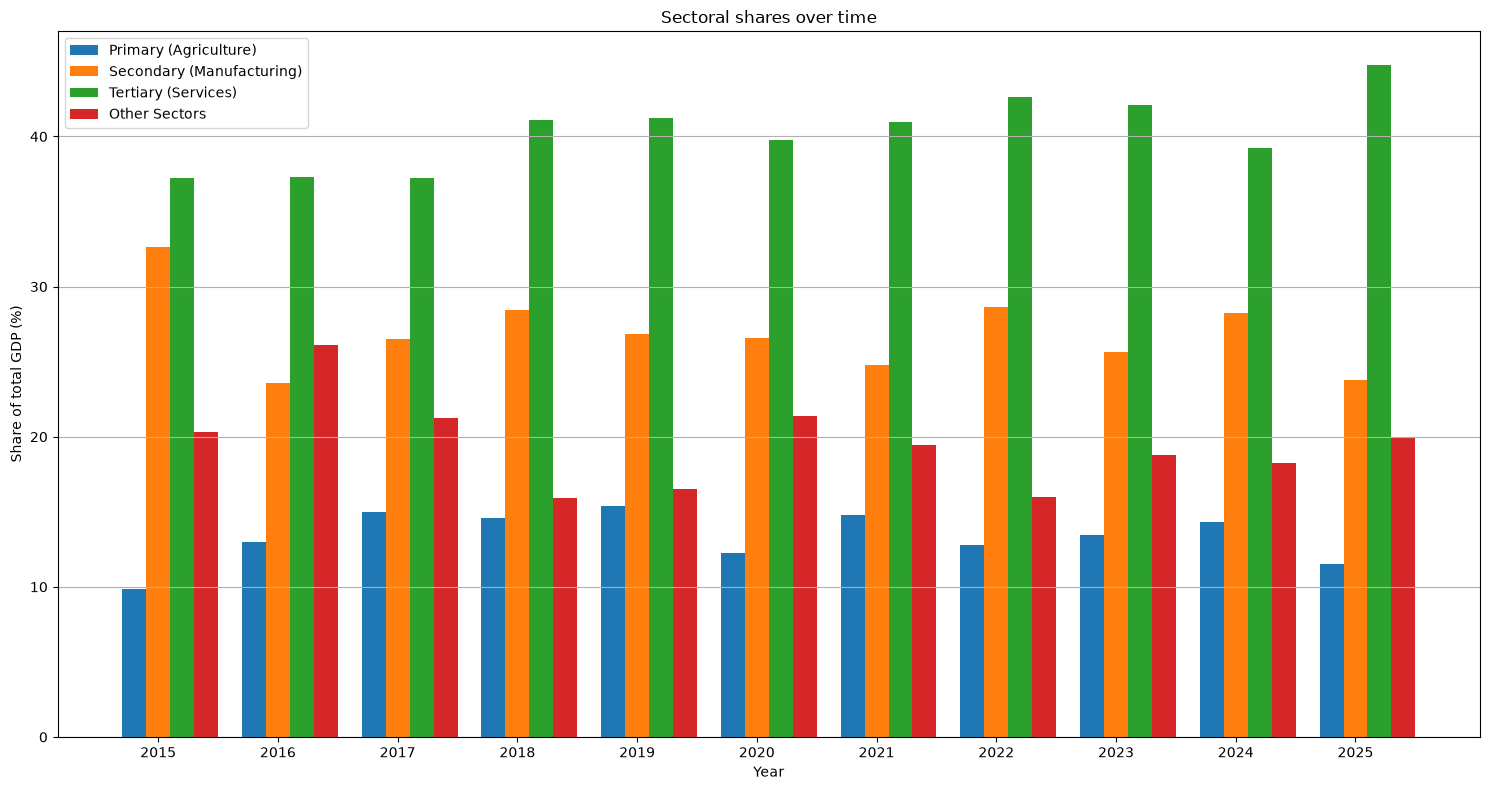

In [ ]:
plt.figure(figsize=(15, 8))

x = np.arange(len(df))
bar_width = 0.2

plt.bar(x - bar_width, df['Primary Sector'], width=bar_width, label='Primary (Agriculture)')
plt.bar(x, df['Secondary Sector'], width=bar_width, label='Secondary (Manufacturing)')
plt.bar(x + bar_width, df['Tertiary Sector'], width=bar_width, label='Tertiary (Services)')
plt.bar(x + 2 * bar_width, df['Other Sector'], width=bar_width, label='Other Sectors')

plt.xticks(x, df['Year'])
plt.xlabel('Year')
plt.ylabel('Share of total GDP (%)')
plt.title('Sectoral shares over time')
plt.legend()
plt.grid(True, axis='y')
plt.tight_layout()
plt.show()


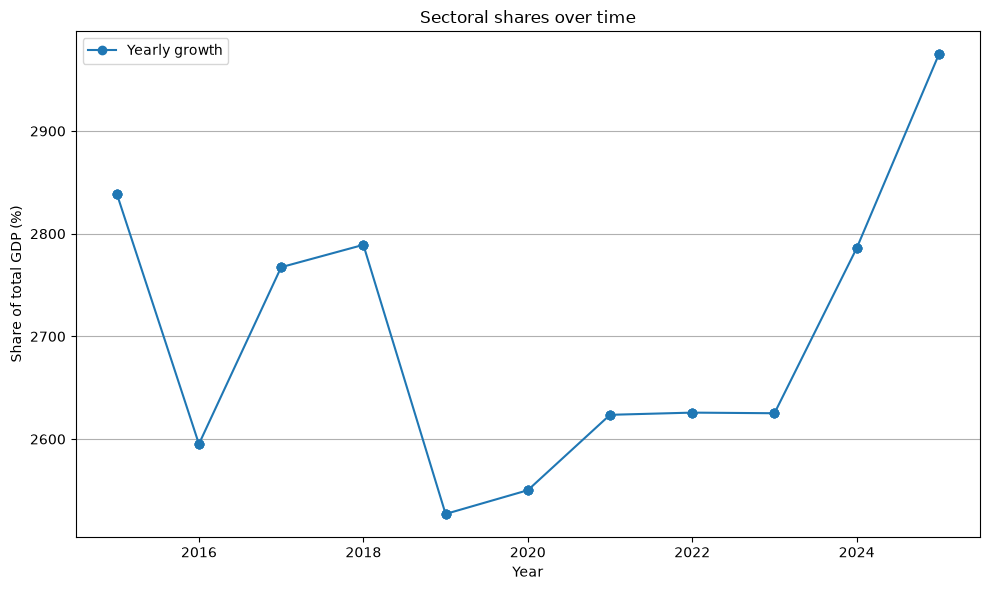

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(g['Year'], g["year_of_total"],   label='Yearly growth', marker='o')



plt.xlabel('Year')
plt.ylabel('Share of total GDP (%)')
plt.title('Sectoral shares over time')
plt.legend()
plt.grid(True, axis='y')
plt.tight_layout()
plt.show()


In [ ]:
g.head()

,Year,Sector_Type,GDP_Lakh_Crore,year_of_total,Percentage_Share
0,2015,Other Sector,576.56,2839.13,20.307629
1,2015,Primary Sector,279.99,2839.13,9.861824
2,2015,Secondary Sector,926.30,2839.13,32.626192
3,2015,Tertiary Sector,1056.28,2839.13,37.204355
4,2016,Other Sector,677.37,2595.17,26.101180


In [ ]:
primary_yearly_growth = g[g['Sector_Type'] == 'Primary Sector'][['Year', "GDP_Lakh_Crore",'Percentage_Share']].reset_index(drop=True)
secondary_yearly_growth = g[g['Sector_Type'] == 'Secondary Sector'][['Year', "GDP_Lakh_Crore",'Percentage_Share']].reset_index(drop=True)
tertiary_yearly_growth = g[g['Sector_Type'] == 'Tertiary Sector'][['Year', "GDP_Lakh_Crore",'Percentage_Share']].reset_index(drop=True)
other_yearly_growth = g[g['Sector_Type'] == 'Other Sector'][['Year', "GDP_Lakh_Crore",'Percentage_Share']].reset_index(drop=True)

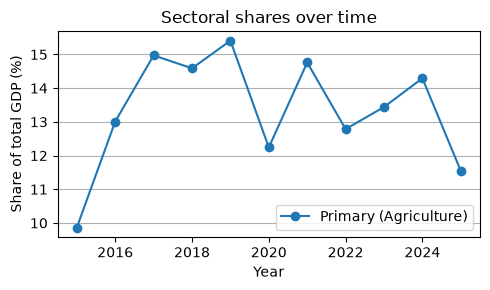

In [ ]:
plt.figure(figsize=(5, 3))
plt.plot(primary_yearly_growth['Year'], primary_yearly_growth['Percentage_Share'],   label='Primary (Agriculture)', marker='o')



plt.xlabel('Year')
plt.ylabel('Share of total GDP (%)')
plt.title('Sectoral shares over time')  
plt.legend()
plt.grid(True, axis='y')
plt.tight_layout()
plt.show()




In [ ]:
pivot

Sector_Type,Other Sector,Primary Sector,Secondary Sector,Tertiary Sector
Year,,,,
2015,20.307629,9.861824,32.626192,37.204355
2016,26.101180,13.009938,23.554141,37.334741
2017,21.272029,14.972592,26.532220,37.223160
2018,15.891881,14.589697,28.416799,41.101622
2019,16.503894,15.408937,26.842472,41.244697
2020,21.378575,12.241929,26.609206,39.770290
2021,19.470501,14.761721,24.798274,40.969504
2022,15.958107,12.784157,28.659621,42.598115
2023,18.803950,13.440045,25.638252,42.117754


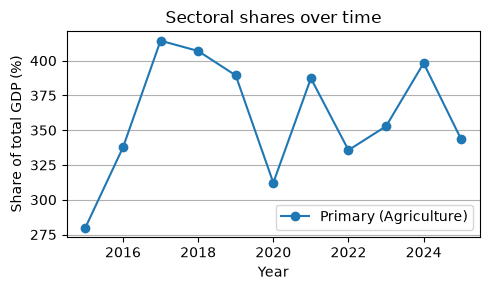

In [ ]:
plt.figure(figsize=(5, 3))
plt.plot(primary_yearly_growth['Year'], primary_yearly_growth['GDP_Lakh_Crore'],   label='Primary (Agriculture)', marker='o')
plt.xlabel('Year')
plt.ylabel('Share of total GDP (%)')
plt.title('Sectoral shares over time')  
plt.legend()
plt.grid(True, axis='y')
plt.tight_layout()
plt.show()


In [ ]:
g.groupby(
    "Year", as_index=False)["Percentage_Share"].sum()

,Year,Percentage_Share
0,2015,100.0
1,2016,100.0
2,2017,100.0
3,2018,100.0
4,2019,100.0
5,2020,100.0
6,2021,100.0
7,2022,100.0
8,2023,100.0
9,2024,100.0


In [ ]:
indian_primary_sectors = indian[indian["Sector"].isin(primary_sectors)]
indian_secondary_sectors = indian[indian["Sector"].isin(secondary_sectors)]
indian_tertiary_sectors = indian[indian["Sector"].isin(tertiary_sectors)]

In [ ]:
print(indian_primary_sectors.groupby("Sector")["GDP_Lakh_Crore"].mean().reset_index(name = "Mean_Growth_Lakh_Crore"))
print(indian_secondary_sectors.groupby("Sector")["GDP_Lakh_Crore"].mean().reset_index(name = "Mean_Growth_Lakh_Crore"))
print(indian_tertiary_sectors.groupby("Sector")["GDP_Lakh_Crore"].mean().reset_index(name = "Mean_Growth_Lakh_Crore"))

        Sector  Mean_Growth_Lakh_Crore
0  Agriculture               42.405455
1       Mining               47.546136
          Sector  Mean_Growth_Lakh_Crore
0   Construction               47.117045
1    Electricity               47.633409
2  Manufacturing               43.071591
3    Real Estate               43.764091
               Sector  Mean_Growth_Lakh_Crore
0       Communication               45.925682
1  Financial Services               44.237955
2          Healthcare               39.839091
3              Retail               48.057500
4             Tourism               48.060000
5           Transport               46.205455


In [ ]:
indian["Sector"].unique()

<StringArray>
[          'Agriculture',         'Manufacturing',          'Construction',
                'Mining',           'Electricity',           'IT Services',
    'Financial Services',                'Retail',            'Healthcare',
             'Education',             'Transport',               'Tourism',
           'Real Estate',         'Communication', 'Public Administration']
Length: 15, dtype: str

In [ ]:
indian.head()

,Year,Quarter,Sector,GDP_Lakh_Crore,Growth_%,Employment_Million,Exports_Crore,Imports_Crore,FDI_Crore,Inflation_%,CPI,IIP,Tax_Revenue_Crore,Time,Month,Date,Sector_Type
0,2015,Q1,Agriculture,29.72,3.94,52.1,107539,126895,27477,4.71,163,95,123957,2015 Q1,3,2015-03-01,Primary Sector
1,2015,Q1,Manufacturing,37.35,9.86,7.7,47744,90509,2292,4.81,121,88,184005,2015 Q1,3,2015-03-01,Secondary Sector
2,2015,Q1,Construction,64.71,6.01,42.4,58226,121494,26803,6.88,114,115,198671,2015 Q1,3,2015-03-01,Secondary Sector
3,2015,Q1,Mining,30.02,9.53,21.4,56195,66624,15163,4.69,158,100,91599,2015 Q1,3,2015-03-01,Primary Sector
4,2015,Q1,Electricity,50.47,9.75,219.5,96330,98575,20985,6.71,130,131,266982,2015 Q1,3,2015-03-01,Secondary Sector
